<center><h1>QBUS2820 - Predictive Analytics</h1></center>

# Tutorial 08 - Ridge Regression

We start by practicing ridge regression for prediction in this tutorial.

We will develop a ridge regression model for predicting house price. The dataset BatonRouge.csv contains 1080 observations. Let's use the variables 'SQFT', 'Bedrooms', 'Baths', 'Age', 'Occupancy', 'Pool', 'Fireplace', 'Waterfront' and 'DOM' as the predictors, and 'Price' for the response variable.

First, import the dataset, and divide it into two sets: training set consists of the first 900 observations and the rest 180 observations form the test set. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import math as ma
from numpy import linalg as LA
from sklearn.linear_model import Ridge 
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error
import numpy as np

n = 900
n_test = 180

data = pd.read_csv("BatonRouge.csv")

# training data
data_training = data.iloc[0:n,:]
print(data_training.head(2))
y = data_training['Price']
X = data_training[['SQFT','Bedrooms','Baths','Age','Occupancy','Pool','Fireplace','Waterfront','DOM']]

# test data
data_test = data.iloc[n:1080,:]
y_test = data_test['Price']
X_test = data_test[['SQFT','Bedrooms','Baths','Age','Occupancy','Pool','Fireplace','Waterfront','DOM']]

   Price  SQFT  Bedrooms  Baths  Age  Occupancy  Pool  Style  Fireplace  \
0  66500   741         1      1   18          1     1      1          1   
1  66000   741         1      1   18          2     1      1          0   

   Waterfront  DOM  
0           0    6  
1           0   23  


Standardize the input for both the training and test data. To simplify the procedure, we also center the response variable so that we do not need to fit an intercept $\beta_0$ in the model.

In [2]:
mu=X.mean() # mean for each feature
sigma=X.std() # std for each feature
X=(X-mu)/sigma
X_test=(X_test-mu)/sigma
y_mean = y.mean()
y = y-y_mean
y_test = y_test-y_mean

Consider the ridge regression problem: Denote by $\hat\beta_\lambda^{ridge}$ the ridge estimate of the coefficients $\beta$ with the ridge parameter $\lambda$. Denote by $y$ the centered output vector and $X$ the standardized input matrix.  

Let $\hat\sigma^2_\lambda=\|y-X\hat\beta_\lambda^{ridge}\|^2/n$, and $d_1^2,...,d_p^2$ be the eigenvalues of $X'X$ and 
$\text{df}(\lambda)=\sum_{j}\frac{d_j^2}{d_j^2+\lambda}$. We have that 

$$\text{AIC}(\lambda)=n\log(\hat\sigma^2_\lambda)+2\text{df}(\lambda),$$

$$\text{BIC}(\lambda)=n\log(\hat\sigma^2_\lambda)+\log(n) \times \text{df}(\lambda).$$

Calculate AIC($\lambda$) and BIC($\lambda$) for $\lambda$ in the range 0.01,0.02,...,39.99,40

We use the function ``eig(np.dot(X.transpose(),X))`` in ``linalg`` for calculating the eigenvalues.

In [3]:
lambdas = np.arange(0.01,40,.01)
def calc_aic_bic(lamb):    
    ridge = Ridge(alpha=lamb, fit_intercept=False)
    ridge.fit(X,y)
    coef = ridge.coef_
    ridge_hat = ridge.predict(X)
    w, v = LA.eig(np.dot(X.transpose(),X))
    df = sum(w/(w+lamb))
    aic = n*np.log( mean_squared_error(y, ridge_hat))+2*df
    bic = n*np.log( mean_squared_error(y, ridge_hat))+np.log(n)*df

    return aic,bic  
    
aic, bic = [], []
for lamb in lambdas:
    aic.append(calc_aic_bic(lamb)[0])
    bic.append(calc_aic_bic(lamb)[1])


**Question**: why didn't we start lambda from 0?

Plot the AIC and BIC curve, and find the optimal $\lambda$ chosen by AIC and BIC methods.

In [4]:
index = np.argmin(aic)
lambda_AIC = lambdas[index]
index = np.argmin(bic)
lambda_BIC = lambdas[index]
[lambda_AIC,lambda_BIC]

[2.64, 9.47]

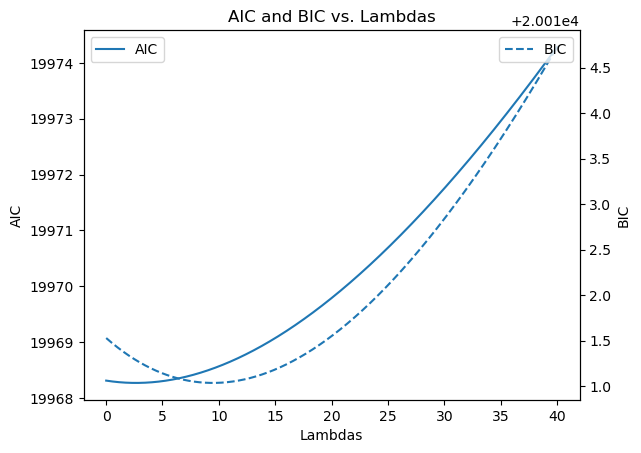

In [5]:
import matplotlib.pyplot as plt

color = '#1f77b4'  # A specific shade of blue

# Create a figure and axis
fig, ax1 = plt.subplots()

# Plot AIC on the left y-axis
ax1.plot(lambdas, aic, color=color, label='AIC')
ax1.set_xlabel('Lambdas')
ax1.set_ylabel('AIC', color='black') 
ax1.tick_params(axis='y', labelcolor='black')

# Create a second y-axis for BIC 
ax2 = ax1.twinx()
ax2.plot(lambdas, bic, color=color, linestyle='--', label='BIC')
ax2.set_ylabel('BIC', color='black')  
ax2.tick_params(axis='y', labelcolor='black')

# Add legends
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Add a title
plt.title('AIC and BIC vs. Lambdas')

# Save the plot
plt.savefig('AIC_BIC_vs_Lambdas.png')

# Show the plot
plt.show()

Caculate the test errors for the ridge regression with respect to the optimal $\lambda$ selected above.  

In [6]:
lr = LinearRegression(fit_intercept=False)
lr.fit(X,y)
y_pre = lr.predict(X_test)
test_error_LR = np.sqrt(np.dot(y_test-y_pre,y_test-y_pre)/n_test)

index = np.argmin(aic)
ridge = Ridge(alpha=lambdas[index], fit_intercept=False)
ridge.fit(X,y)
y_pre = ridge.predict(X_test)
test_error_AIC = np.sqrt(np.dot(y_test-y_pre,y_test-y_pre)/n_test)

index = np.argmin(bic)
ridge = Ridge(alpha=lambdas[index], fit_intercept=False)
ridge.fit(X,y)
y_pre = ridge.predict(X_test)
test_error_BIC = np.sqrt(np.dot(y_test-y_pre,y_test-y_pre)/n_test)

results=pd.DataFrame(columns=['lambda','Test error'], index=['LR','AIC', 'BIC'], dtype='float64') 


results.iloc[0, 0] = 0
results.iloc[1, 0] = lambda_AIC
results.iloc[2, 0] = lambda_BIC

results.iloc[0, 1] = test_error_LR
results.iloc[1, 1] = test_error_AIC
results.iloc[2, 1] = test_error_BIC

results

,lambda,Test error
LR,0.00,111371.174524
AIC,2.64,111337.093540
BIC,9.47,111269.456779
